__Задача 1__

__Пункт 1__

In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from rink import plot_rink

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['savefig.bbox'] = 'tight'
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 80)
os.makedirs('figures', exist_ok=True)

In [15]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)

rename = {
    'Game ID': 'GameID',
    'Cumulated Away Score': 'AwayScore',
    'Cumulated Home Score': 'HomeScore',
    'Away Team': 'AwayTeam',
    'Home Team': 'HomeTeam',
    'Elapsed Time': 'ElapsedTime',
    'Remaining Time': 'RemainingTime',
    'Play ID': 'PlayID',
    'Play Length': 'PlayLength',
    'Play Type': 'PlayType',
    'Play Subtype': 'PlaySubtype',
    'Play Zone': 'PlayZone',
    'Team Making the Play': 'TeamMakingthePlay',
    'Player in the Event #1': 'Player1',
    'Player in the Event #2': 'Player2',
    'Player in the Event #3': 'Player3',
    'X Coordinate on the Ice Rink': 'X',
    'Y Coordinate on the Ice Rink': 'Y',
    "# of Away Team's Players on the Ice": 'AwayNum',
    "# of Home Team's Players on the Ice": 'HomeNum',
    "Away Team's Goalie": 'AwayGoalie',
    "Home Team's Goalie": 'HomeGoalie',
    "Home Team's Defending Side": 'HomeDefendingSide',
}
for side in ['Away', 'Home']:
    for k in range(1, 7):
        rename[f"{side} Team's Player on the Ice #{k}"] = f'{side}Skater{k}'
events = events.rename(columns=rename)

print(events.shape)
events.iloc[:10, [2, 3, 4, 9, 12]]

(29710, 38)


,Date,AwayTeam,HomeTeam,RemainingTime,PlayType
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


В исходной таблице 29 710 событий и 38 столбцов. Данные охватывают 82 матча всех четырёх раундов плей-офф с 19 апреля по 14 июня 2026 года. В турнире участвовали 16 команд, встречаются 14 типов событий. Чаще всего фиксировались силовые приёмы (5 621), вбрасывания (4 995), броски в створ (4 137) и остановки игры (3 958). Всего в таблице 486 голов. Событий начала и окончания периодов, по 272: это три периода в каждой игре и ещё 26 овертаймных периодов.

__Пункт 2__

In [16]:
ends = events[events['PlayType'] == 'game-end'].set_index('GameID')
n_ot = ends['Period'] - 3
outcome = ['Final' if k <= 0 else ('Final/OT' if k == 1 else f'Final/{k}OT') for k in n_ot]

games = pd.DataFrame({
    'Date': ends['Date'],
    'AwayTeam': ends['AwayTeam'],
    'HomeTeam': ends['HomeTeam'],
    'AwayScore': ends['AwayScore'],
    'HomeScore': ends['HomeScore'],
    'Outcome': outcome,
}).sort_index()

goal_cnt = events[events['PlayType'] == 'goal'].groupby('GameID').size().reindex(games.index, fill_value=0)
assert (goal_cnt == games['AwayScore'] + games['HomeScore']).all()
assert (games['AwayScore'] != games['HomeScore']).all()

print(games.columns)
games.iloc[-5:, -4:]

Index(['Date', 'AwayTeam', 'HomeTeam', 'AwayScore', 'HomeScore', 'Outcome'], dtype='object')


,HomeTeam,AwayScore,HomeScore,Outcome
GameID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


Итоговый счёт берётся из события game-end, а количество овертаймов определяется по номеру последнего периода за вычетом трёх. В поле Outcome записывается Final, Final/OT или Final/2OT. В основное время завершились 60 матчей, в одном овертайме - 18, ещё 4 дошли до второго овертайма. Таким образом, овертайм был примерно в каждом четвёртом матче.

__Пункт 3__

In [17]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (f"{g['HomeTeam']}-{g['AwayTeam']} "
            f"({g['HomeScore']}-{g['AwayScore']}, {g['Outcome']}, {g['Date']})")

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))
games['Outcome'].value_counts()

Buffalo Sabres-Boston Bruins (4-3, Final, 2026-04-19)
Vegas Golden Knights-Carolina Hurricanes (0-3, Final, 2026-06-14)


Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64

Функция выводит сначала хозяев, затем гостей. Счёт записан в том же порядке. После него идут результат матча и дата. 

__Пункт 4__

In [18]:
games['TotalScore'] = games['AwayScore'] + games['HomeScore']
print(games['TotalScore'].describe())
print('Мода:', games['TotalScore'].mode().tolist(), '| дисперсия:', round(games['TotalScore'].var(), 3))

count    82.000000
mean      5.926829
std       2.259578
min       1.000000
25%       5.000000
50%       6.000000
75%       7.000000
max      15.000000
Name: TotalScore, dtype: float64
Мода: [5] | дисперсия: 5.106


В среднем команды забивали 5,93 шайбы за матч. Медиана равна 6, мода - 5, стандартное отклонение - 2,26. Зафиксированный диапазон - от 1 до 15 голов.

__Пункт 5__

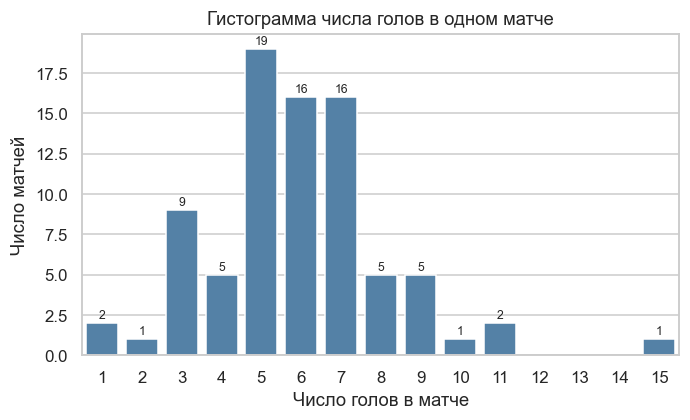

Доля матчей с 5-7 голами: 0.622
Доля матчей с >=9 голами: 0.11
Асимметрия: 0.777
Мат. ожидание / дисперсия: 5.927 / 5.106


In [20]:
fig, ax = plt.subplots(figsize=(7, 3.8))
order = range(games['TotalScore'].min(), games['TotalScore'].max() + 1)
sns.countplot(data=games, x='TotalScore', order=order, color='steelblue', ax=ax)
ax.set_xlabel('Число голов в матче')
ax.set_ylabel('Число матчей')
ax.set_title('Гистограмма числа голов в одном матче')
ax.bar_label(ax.containers[0], padding=1, fontsize=8)
fig.savefig('figures/fig1_total_goals.png')
plt.show()

ts = games['TotalScore']
print('Доля матчей с 5-7 голами:', round(ts.between(5, 7).mean(), 3))
print('Доля матчей с >=9 голами:', round((ts >= 9).mean(), 3))
print('Асимметрия:', round(ts.skew(), 3))
print('Мат. ожидание / дисперсия:', round(ts.mean(), 3), '/', round(ts.var(), 3))

На гистограмме заметен один основной пик и более длинный хвост справа. Чаще всего в матче забивали пять голов - таких игр было 19. Счёт с шестью или семью голами встречался по 16 раз. В сумме на эти три значения приходится около 62% матчей. Асимметрия положительная (0,78), её создают редкие результативные игры. В девяти матчах было забито не меньше девяти шайб, а рекорд в 15 голов пришёлся на встречу Colorado Avalanche и Minnesota Wild, завершившуюся со счётом 9:6. Нижняя граница распределения объясняется правилами плей-офф: матч не может закончиться вничью, а при равном счёте команды продолжают играть до гола. Поэтому меньше одной шайбы за игру быть не может. Два матча с единственной шайбой закончились в овертайме. Дисперсия равна 5,11 при среднем 5,93; отношение этих значений составляет 0,86. Разброс близок к пуассоновскому, хотя нижняя граница в один гол немного ограничивает распределение.

__Пункт 6__

In [22]:
lo = games.index[games['TotalScore'] == games['TotalScore'].min()]
hi = games.index[games['TotalScore'] == games['TotalScore'].max()]
print('Минимум голов:', games['TotalScore'].min())
print([gameInfo(i) for i in lo])
print('Максимум голов:', games['TotalScore'].max())
print([gameInfo(i) for i in hi])

Минимум голов: 1
['Montréal Canadiens-Tampa Bay Lightning (0-1, Final/OT, 2026-05-01)', 'Philadelphia Flyers-Pittsburgh Penguins (1-0, Final/OT, 2026-04-29)']
Максимум голов: 15
['Colorado Avalanche-Minnesota Wild (9-6, Final, 2026-05-03)']


Минимальный результат '1:0'  был зафиксирован в двух матчах, и оба завершились в овертайме. Самый результативный матч был один. 

__Пункт 7__

In [26]:
skater_cols = [f'{s}Skater{k}' for s in ['Away', 'Home'] for k in range(1, 7)]
goalie_cols = ['AwayGoalie', 'HomeGoalie']
onice_cols = skater_cols + goalie_cols

onice = events.melt(id_vars='GameID', value_vars=onice_cols, var_name='Slot', value_name='Player')
onice = onice.dropna(subset=['Player'])
onice['Side'] = onice['Slot'].str[:4]        
onice['IsGoalie'] = onice['Slot'].str.endswith('Goalie')

player_count = onice.drop_duplicates(['GameID', 'Side', 'Player']).groupby('GameID').size()
pc = pd.DataFrame({'GameInfo': [gameInfo(i) for i in games.index],
                   'PlayerCount': player_count.reindex(games.index)}, index=games.index)
print(pc['PlayerCount'].describe())
pc.sort_values('PlayerCount', ascending=False).head(10)

count    82.000000
mean     38.121951
std       0.364818
min      38.000000
25%      38.000000
50%      38.000000
75%      38.000000
max      40.000000
Name: PlayerCount, dtype: float64


,GameInfo,PlayerCount
GameID,,
2025030216,"Montréal Canadiens-Buffalo Sabres (3-8, Final, 2026-05-16)",40
2025030215,"Buffalo Sabres-Montréal Canadiens (3-6, Final, 2026-05-14)",39
2025030243,"Anaheim Ducks-Vegas Golden Knights (2-6, Final, 2026-05-08)",39
2025030233,"Minnesota Wild-Colorado Avalanche (5-1, Final, 2026-05-09)",39
2025030235,"Colorado Avalanche-Minnesota Wild (4-3, Final/OT, 2026-05-13)",39
2025030112,"Buffalo Sabres-Boston Bruins (2-4, Final, 2026-04-21)",39
2025030413,"Vegas Golden Knights-Carolina Hurricanes (5-4, Final/2OT, 2026-06-06)",39
2025030114,"Boston Bruins-Buffalo Sabres (1-6, Final, 2026-04-26)",39
2025030185,"Edmonton Oilers-Anaheim Ducks (4-1, Final, 2026-04-28)",39


In [27]:
gid = pc['PlayerCount'].idxmax()
tmp = onice[onice['GameID'] == gid]
raw = pd.unique(events.loc[events['GameID'] == gid, onice_cols].to_numpy().ravel())
print('Игра', gid, '| уникальных игроков:', tmp.drop_duplicates(['Side', 'Player']).shape[0],
      '| уникальных значений вместе с NaN:', len(raw))

Игра 2025030216 | уникальных игроков: 40 | уникальных значений вместе с NaN: 41


Больше всего игроков - 40 - было в матче Montréal Canadiens - Buffalo Sabres (3:8, 16 мая) - в этой игре обе команды меняли вратаря. В 73 матчах участвовали по 38 игроков - по 18 полевых и одному вратарю от каждой команды. Ещё в восьми матчах было 39 игроков, а в одном - 40. Всего замены вратаря происходили в девяти играх. Если считать пустую ячейку NaN за игрока, для этого матча получится 41 человек. Пустая ячейка не означает дополнительного игрока, поэтому корректный результат здесь - 40. В коде для сравнения выведены оба значения.

__Пункт 8__

In [29]:
SHOT_TYPES = ['shot-on-goal', 'goal', 'missed-shot']
is_shot = events['PlayType'].isin(SHOT_TYPES)
sh = events[is_shot]

shooter_is_home = sh['TeamMakingthePlay'] == sh['HomeTeam']
home_attacks_right = sh['HomeDefendingSide'] == 'left'
goal_x = np.where(shooter_is_home == home_attacks_right, 89, -89)

dy = np.where(sh['Y'] < -3, sh['Y'] + 3, np.where(sh['Y'] > 3, sh['Y'] - 3, 0.0))
events['ShotLength'] = np.nan
events.loc[is_shot, 'ShotLength'] = np.hypot(sh['X'] - goal_x, dy)
events['AttackedGoalX'] = np.nan
events.loc[is_shot, 'AttackedGoalX'] = goal_x

same_side = (np.sign(sh['X']) == np.sign(goal_x)) | (sh['X'] == 0)
print('Доля бросков, совершённых с половины, где находятся атакуемые ворота:', round(same_side.mean(), 4))
print('Доля бросков, у которых PlayZone == Offensive:', round((sh['PlayZone'] == 'Offensive').mean(), 4))

events[events['PlayType'].isin(SHOT_TYPES)][['GameID', 'PlayType', 'ShotLength']]

Доля бросков, совершённых с половины, где находятся атакуемые ворота: 0.9708
Доля бросков, у которых PlayZone == Offensive: 0.9491


,GameID,PlayType,ShotLength
7,2025030111,missed-shot,12.206556
9,2025030111,missed-shot,12.000000
12,2025030111,missed-shot,29.410882
13,2025030111,shot-on-goal,62.169124
19,2025030111,missed-shot,52.924474
...,...,...,...
29695,2025030416,missed-shot,54.083269
29696,2025030416,missed-shot,5.099020
29704,2025030416,goal,46.238512
29706,2025030416,missed-shot,60.926185


В 97,1% случаев бросающий находится на той половине площадки, где расположены атакуемые им ворота; у 94,9% бросков зона отмечена как Offensive. Остальные случаи могут быть дальними бросками из своей или нейтральной зоны. Эта проверка поддерживает выбранный способ определения атакуемых ворот.

__Пункт 9__

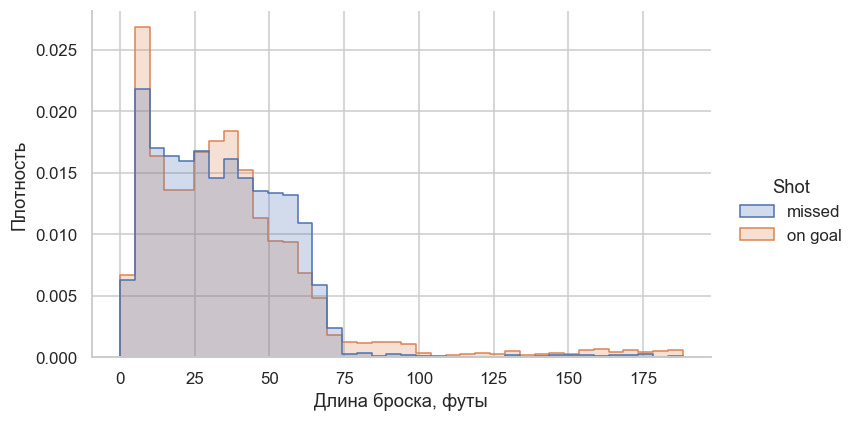

          count   mean    std  min    25%    50%    75%     max
Shot                                                           
missed   2643.0  34.01  22.31  0.0  16.16  32.25  49.04  185.07
on goal  4623.0  36.21  30.00  0.0  15.00  31.83  47.01  188.22

Доля бросков длиннее 60 футов: {'missed': 0.104, 'on goal': 0.1285}
Доля бросков длиннее 89 футов: {'missed': 0.0114, 'on goal': 0.0478}
Доля бросков длиннее 100 футов: {'missed': 0.0087, 'on goal': 0.0346}


In [30]:
shots = events[is_shot].copy()
shots['Shot'] = np.where(shots['PlayType'] == 'missed-shot', 'missed', 'on goal')

g = sns.displot(data=shots, x='ShotLength', hue='Shot', hue_order=['missed', 'on goal'],
                stat='density', common_norm=False, binwidth=5, element='step',
                height=4, aspect=1.7)
g.set_axis_labels('Длина броска, футы', 'Плотность')
g.fig.savefig('figures/fig3_shot_length.png')
plt.show()

print(shots.groupby('Shot')['ShotLength'].describe().round(2))
print()
for thr in (60, 89, 100):
    print(f'Доля бросков длиннее {thr} футов:',
          shots.groupby('Shot')['ShotLength'].apply(lambda s: round((s > thr).mean(), 4)).to_dict())

In [31]:
mm = shots['RemainingTime'].str.split(':', expand=True).astype(int)
shots['RemSec'] = mm[0] * 60 + mm[1]                              
home_shot = shots['TeamMakingthePlay'] == shots['HomeTeam']
lead = np.where(home_shot, shots['HomeScore'] - shots['AwayScore'], shots['AwayScore'] - shots['HomeScore'])
shots['ShooterLead'] = lead - (shots['PlayType'] == 'goal').astype(int)   
shots['Late'] = (shots['Period'] >= 3) & (shots['RemSec'] <= 360)      

far = shots[shots['ShotLength'] > 89]
print('Бросков дальше 89 футов:', far['PlayType'].value_counts().to_dict())
tail = far.groupby('PlayType').apply(lambda d: pd.Series({
    'N': len(d),
    'в конце игры (посл. 6 мин)': round(d['Late'].mean(), 3),
    'бросает ведущая команда': round((d['ShooterLead'] > 0).mean(), 3),
    'бросает проигрывающая': round((d['ShooterLead'] < 0).mean(), 3)}), include_groups=False)
base = pd.Series({'N': len(shots), 'в конце игры (посл. 6 мин)': round(shots['Late'].mean(), 3),
                  'бросает ведущая команда': round((shots['ShooterLead'] > 0).mean(), 3),
                  'бросает проигрывающая': round((shots['ShooterLead'] < 0).mean(), 3)}, name='ВСЕ броски (для сравнения)')
print(pd.concat([tail, base.to_frame().T]))

far_goals = far[far['PlayType'] == 'goal']
print('\nГолов дальше 89 футов:', len(far_goals),
      '| из них в последние 6 минут и при перевесе бросавшей команды:',
      int((far_goals['Late'] & (far_goals['ShooterLead'] > 0)).sum()))
print(far_goals[['GameID', 'Period', 'RemainingTime', 'ShooterLead', 'ShotLength']].round(1).to_string())
far_sog = far[far['PlayType'] == 'shot-on-goal']
print('\nДальние броски в створ (не голы):', len(far_sog), '| подтипы:', far_sog['PlaySubtype'].value_counts().to_dict())

Бросков дальше 89 футов: {'shot-on-goal': 202, 'missed-shot': 30, 'goal': 19}
                                 N  в конце игры (посл. 6 мин)  бросает ведущая команда  бросает проигрывающая
goal                          19.0                       0.947                    1.000                  0.000
missed-shot                   30.0                       0.767                    0.900                  0.000
shot-on-goal                 202.0                       0.099                    0.282                  0.322
ВСЕ броски (для сравнения)  7266.0                       0.104                    0.266                  0.324

Голов дальше 89 футов: 19 | из них в последние 6 минут и при перевесе бросавшей команды: 18
           GameID  Period RemainingTime  ShooterLead  ShotLength
587    2025030112       2         03:31            1        89.1
2169   2025030116       3         03:20            2        89.1
10308  2025030161       3         03:08            4       116.1
10669  2025030

В целом распределения похожи: у обоих есть пик на расстоянии 5-10 футов и ещё один подъём примерно на 25-40 футах. Медианы почти одинаковы - 32,2 и 31,8 фута. Разница заметнее на отдельных дистанциях: промахи чаще встречаются на 50-65 футах (18,7% против 12,5%), а точные броски немного чаще - на 30-40 футах и рядом с воротами. Отдельно выделяются броски дальше 89 футов: среди точных их 221 (4,8%), среди промахов - 30 (1,1%). Доля попаданий в створ по дистанции меняется неравномерно: на 50-70 футах она падает до 54-55%, затем растёт до 77% на 70-89 футах и до 88% за отметкой 89 футов.

Чтобы разобраться с длинным хвостом точных бросков отдельно были рассмотрены события дальше 89 футов. Одна из возможных причин - 
голы в пустые ворота. Для проверки было сопоставлено расстояние со временем матча и текущим счётом. Из 19 голов, забитых с расстояния больше 89 футов, 18 пришлись на последние шесть минут третьего периода или на овертайм. Во всех этих случаях забившая команда уже вела в счёте - это похоже на голы в пустые ворота после снятия вратаря. Оставшийся гол был забит с 89,1 фута во втором периоде при времени 3:31; он, вероятно, был обычным дальним броском. Похожая картина есть и у дальних промахов: 77% приходятся на концовку, когда команда не проигрывает. При этом вратарь всё ещё указан в большинстве таких записей: пустое поле есть только у 3 из 19 голов. Поэтому по одному столбцу вратаря определить пустые ворота нельзя - приходится учитывать время и счёт.

__Пункт 10__

In [32]:
shots['OnGoal'] = (shots['PlayType'] != 'missed-shot').astype(int)
numshots = shots.groupby(['GameID', 'TeamMakingthePlay']).agg(
    Attempts=('OnGoal', 'size'), OnGoal=('OnGoal', 'sum'))
numshots['ShareofShotsonGoal'] = numshots['OnGoal'] / numshots['Attempts']
print(numshots['ShareofShotsonGoal'].round(3))
print()
print(numshots['ShareofShotsonGoal'].describe().round(3))

GameID      TeamMakingthePlay   
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: ShareofShotsonGoal, Length: 164, dtype: float64

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: ShareofShotsonGoal, dtype: float64


Общая доля точных бросков: 0.6363
Среднее число незаблокированных бросков команды за игру: 44.3
Ожидаемое стд. откл. доли при чисто случайных бросках (биномиальная модель): 0.0739
Наблюдаемое стд. откл. доли: 0.085
        mean    std  count
Won                       
False  0.646  0.083     82
True   0.632  0.087     82
t-тест Уэлча (победители vs проигравшие): TtestResult(statistic=np.float64(-1.0147265649019368), pvalue=np.float64(0.3117520075889636), df=np.float64(161.71035114727076))


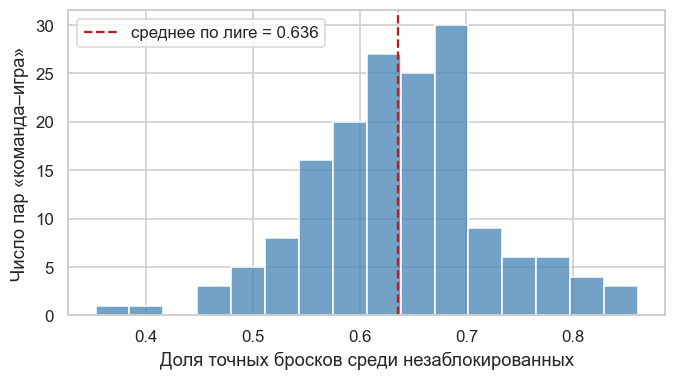

In [33]:
p = numshots['OnGoal'].sum() / numshots['Attempts'].sum()
n_mean = numshots['Attempts'].mean()
sd_binom = np.sqrt(p * (1 - p) / numshots['Attempts']).mean()
print('Общая доля точных бросков:', round(p, 4))
print('Среднее число незаблокированных бросков команды за игру:', round(n_mean, 1))
print('Ожидаемое стд. откл. доли при чисто случайных бросках (биномиальная модель):', round(sd_binom, 4))
print('Наблюдаемое стд. откл. доли:', round(numshots['ShareofShotsonGoal'].std(), 4))

res = games[['AwayTeam', 'HomeTeam', 'AwayScore', 'HomeScore']].copy()
res['Winner'] = np.where(res['HomeScore'] > res['AwayScore'], res['HomeTeam'], res['AwayTeam'])
ns = numshots.reset_index().merge(res['Winner'].reset_index(), on='GameID')
ns['Won'] = ns['TeamMakingthePlay'] == ns['Winner']
print(ns.groupby('Won')['ShareofShotsonGoal'].agg(['mean', 'std', 'count']).round(3))
print('t-тест Уэлча (победители vs проигравшие):',
      stats.ttest_ind(ns.loc[ns.Won, 'ShareofShotsonGoal'], ns.loc[~ns.Won, 'ShareofShotsonGoal'], equal_var=False))

fig, ax = plt.subplots(figsize=(7, 3.6))
sns.histplot(numshots['ShareofShotsonGoal'], bins=16, color='steelblue', ax=ax)
ax.axvline(p, color='firebrick', ls='--', label=f'среднее по лиге = {p:.3f}')
ax.set_xlabel('Доля точных бросков среди незаблокированных')
ax.set_ylabel('Число пар «команда–игра»')
ax.legend()
fig.savefig('figures/fig_share_hist.png')
plt.show()

В среднем в створ попадает около 64% незаблокированных бросков команды: среднее и медиана равны 0,639, а общий показатель по лиге составляет 0,636. Значения лежат в диапазоне от 0,353 до 0,860; стандартное отклонение составляет 0,085. Часть разброса может быть случайной. При среднем числе 44,3 броска и вероятности попадания 0,636 биномиальное стандартное отклонение доли составляет 0,074. Оно близко к наблюдаемому 0,085, поэтому большую часть различий можно объяснить обычной вариацией от матча к матчу.
По этим данным точность не показывает заметной связи с победой. У победителей доля бросков в створ составляет 0,632, у проигравших 0,646; тест Уэлча даёт p = 0,31. Разница небольшая и статистически неубедительная. Сам по себе процент попаданий в створ не объясняет исход: важны также количество и качество бросков, а ещё игра вратарей.


__Пункт 11__

In [35]:
avgnumshots = numshots['ShareofShotsonGoal'].groupby(level='TeamMakingthePlay').mean()
print(avgnumshots.nlargest(5).round(3))
print()
print(avgnumshots.nsmallest(5).round(3))

TeamMakingthePlay
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: ShareofShotsonGoal, dtype: float64

TeamMakingthePlay
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: ShareofShotsonGoal, dtype: float64


In [39]:
team_tbl = numshots.groupby(level='TeamMakingthePlay').agg(
    Games=('Attempts', 'size'), Attempts=('Attempts', 'sum'), OnGoal=('OnGoal', 'sum'))
team_tbl['AvgShare'] = avgnumshots
team_tbl['PooledShare'] = team_tbl['OnGoal'] / team_tbl['Attempts']
team_tbl['SE'] = np.sqrt(p * (1 - p) / team_tbl['Attempts'])     
team_tbl['z'] = (team_tbl['PooledShare'] - p) / team_tbl['SE']
print(team_tbl.sort_values('AvgShare', ascending=False).round(3))

groups = [grp['ShareofShotsonGoal'].to_numpy() for _, grp in numshots.groupby(level='TeamMakingthePlay')]
print('ANOVA:', stats.f_oneway(*groups))
print('Краскел–Уоллис:', stats.kruskal(*groups))
chi2 = ((team_tbl['OnGoal'] - p * team_tbl['Attempts']) ** 2 /
        (p * (1 - p) * team_tbl['Attempts'])).sum()
print('Хи-квадрат однородности (по пулу бросков), df=15: chi2 =', round(chi2, 2),
      ', p =', round(1 - stats.chi2.cdf(chi2, 15), 4))

                      Games  Attempts  OnGoal  AvgShare  PooledShare     SE      z
TeamMakingthePlay                                                                 
Edmonton Oilers           6       243     170     0.706        0.700  0.031  2.052
Philadelphia Flyers      10       361     246     0.684        0.681  0.025  1.785
Dallas Stars              6       278     186     0.670        0.669  0.029  1.137
Minnesota Wild           11       481     316     0.656        0.657  0.022  0.944
Colorado Avalanche       13       644     418     0.653        0.649  0.019  0.676
Anaheim Ducks            12       586     380     0.649        0.648  0.020  0.615
Montréal Canadiens       19       682     442     0.644        0.648  0.018  0.643
Los Angeles Kings         4       158     101     0.642        0.639  0.038  0.078
Boston Bruins             6       237     151     0.638        0.637  0.031  0.028
Ottawa Senators           4       178     110     0.635        0.618  0.036 -0.507
Vega

На первый взгляд разница заметная: у Edmonton Oilers средняя доля точных бросков - 0,706, у Pittsburgh Penguins - 0,554. Но у лидеров выборки мало матчей: Edmonton и Dallas сыграли по шесть, Philadelphia - десять. Для сравнения, Vegas провёл 22 игры и оказался ближе к середине списка (0,626), а Carolina после 19 матчей попала в нижнюю пятёрку (0,615). При небольшом числе наблюдений крайние значения могут возникать случайно. Это согласуется и со статистическими тестами: ANOVA даёт p = 0,27, тест Краскела-Уоллиса - p = 0,31, а проверка однородности по всем броскам - p = 0,077. Pittsburgh выделяется сильнее остальных (z = -2,9; p ≈ 0,004), но после поправки Бонферрони для 16 сравнений порог равен примерно 0,003, и результат его не достигает. Поэтому по этому плей-офф нельзя уверенно сказать, что одни команды стабильно точнее других.

__Пункт 12__

In [40]:
tg = pd.concat([
    games[['AwayTeam']].rename(columns={'AwayTeam': 'Team'}),
    games[['HomeTeam']].rename(columns={'HomeTeam': 'Team'})
]).reset_index().rename(columns={'index': 'GameID'})
full_idx = pd.MultiIndex.from_frame(tg[['GameID', 'Team']], names=['GameID', 'TeamMakingthePlay'])

sog = events[events['PlayType'].isin(['shot-on-goal', 'goal'])].groupby(['GameID', 'TeamMakingthePlay']).size()
sog_only = events[events['PlayType'] == 'shot-on-goal'].groupby(['GameID', 'TeamMakingthePlay']).size()
gls = events[events['PlayType'] == 'goal'].groupby(['GameID', 'TeamMakingthePlay']).size()

per_game = pd.DataFrame({
    'Shot': sog.reindex(full_idx, fill_value=0),
    'ShotOnlySOG': sog_only.reindex(full_idx, fill_value=0),
    'Goal': gls.reindex(full_idx, fill_value=0)})
avgshots_all = per_game.groupby(level='TeamMakingthePlay').mean()
avgshots = avgshots_all[['Shot', 'Goal']]
print(avgshots.round(3))


                        Shot   Goal
TeamMakingthePlay                  
Anaheim Ducks         31.667  3.250
Boston Bruins         25.167  2.000
Buffalo Sabres        30.462  3.308
Carolina Hurricanes   31.632  3.474
Colorado Avalanche    32.154  3.385
Dallas Stars          31.000  2.500
Edmonton Oilers       28.333  3.500
Los Angeles Kings     25.250  1.250
Minnesota Wild        28.727  3.727
Montréal Canadiens    23.263  2.842
Ottawa Senators       27.500  1.250
Philadelphia Flyers   24.600  2.100
Pittsburgh Penguins   26.500  1.833
Tampa Bay Lightning   28.000  2.143
Utah Mammoth          27.833  3.000
Vegas Golden Knights  26.545  3.455


__Пункт 13__

Пирсон: r = 0.521, p = 0.039; наклон = 0.156 ± 0.069 гола на бросок
Спирмен: rho = 0.578, p = 0.019; R^2 = 0.271
По парам команда–игра (n=164): r = 0.196, p = 0.012, наклон = 0.046 ± 0.018


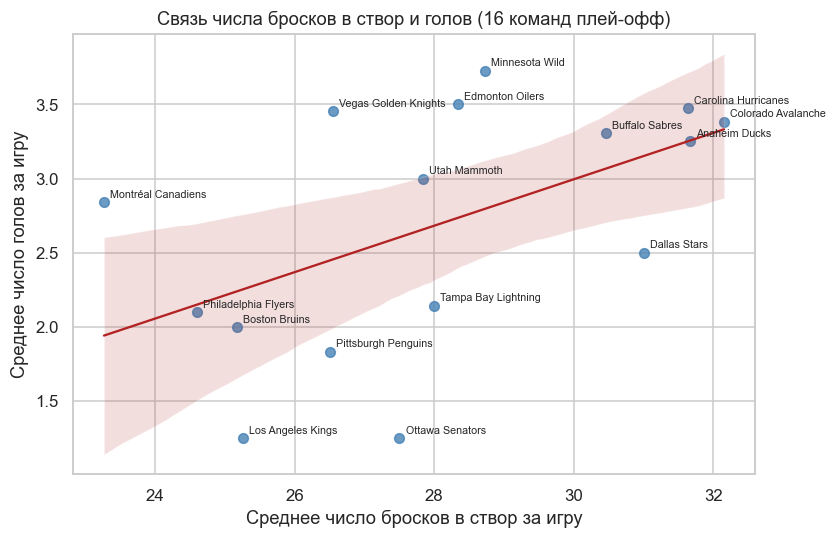

In [41]:
x, y = avgshots['Shot'], avgshots['Goal']
lr = stats.linregress(x, y)
rho, p_rho = stats.spearmanr(x, y)
print(f'Пирсон: r = {lr.rvalue:.3f}, p = {lr.pvalue:.3f}; наклон = {lr.slope:.3f} ± {lr.stderr:.3f} гола на бросок')
print(f'Спирмен: rho = {rho:.3f}, p = {p_rho:.3f}; R^2 = {lr.rvalue**2:.3f}')

pg = per_game.reset_index()
lr_g = stats.linregress(pg['Shot'], pg['Goal'])
print(f'По парам команда–игра (n={len(pg)}): r = {lr_g.rvalue:.3f}, p = {lr_g.pvalue:.2g}, '
      f'наклон = {lr_g.slope:.3f} ± {lr_g.stderr:.3f}')

fig, ax = plt.subplots(figsize=(8, 5.2))
sns.regplot(x=x, y=y, ci=95, scatter_kws={'s': 40, 'color': 'steelblue'},
            line_kws={'color': 'firebrick', 'lw': 1.5}, ax=ax)
for team, (xi, yi) in avgshots[['Shot', 'Goal']].iterrows():
    ax.annotate(team, (xi, yi), xytext=(4, 3), textcoords='offset points', fontsize=7)
ax.set_xlabel('Среднее число бросков в створ за игру')
ax.set_ylabel('Среднее число голов за игру')
ax.set_title('Связь числа бросков в створ и голов (16 команд плей-офф)')
fig.savefig('figures/fig4_regplot.png')
plt.show()

Между средним числом бросков в створ и средним числом голов есть положительная, но не очень сильная связь. Корреляция Пирсона равна r = 0,52 (p = 0,039), корреляция Спирмена - ρ = 0,58 (p = 0,019). По линии регрессии один дополнительный бросок связан примерно с 0,16 дополнительного гола в среднем; R² ≈ 0,27. Иными словами, число бросков объясняет чуть больше четверти различий между командами. Остальное может зависеть от качества моментов, действий вратарей и случайности.

__Пункт 14__

In [44]:
ATTEMPTS = ['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot']
att = events[events['PlayType'].isin(ATTEMPTS)]
att_per_game = att.groupby('GameID').size()
idxmax = att_per_game.idxmax()
print(gameInfo(idxmax), '| ударов:', att_per_game.max())
print(att_per_game.describe().round(1))
print(att_per_game.nlargest(5).rename('Attempts').to_frame().assign(GameInfo=lambda d: [gameInfo(i) for i in d.index]))

end = events[events['PlayType'] == 'game-end'].set_index('GameID')
mmss = end['ElapsedTime'].str.split(':', expand=True).astype(int)
duration = (end['Period'] - 1) * 20 + mmss[0] + mmss[1] / 60
per60 = (att_per_game / duration * 60).rename('AttemptsPer60')
print('Длительность игры', idxmax, ':', round(duration[idxmax], 1), 'мин; корреляция числа ударов и длительности:',
      round(np.corrcoef(att_per_game, duration)[0, 1], 3))
print('Средний темп ударов на 60 минут:', round(per60.mean(), 1), '| темп в игре', idxmax, ':', round(per60[idxmax], 1))
print(per60.nlargest(3).round(1).to_frame().assign(GameInfo=lambda d: [gameInfo(i) for i in d.index]))

Carolina Hurricanes-Ottawa Senators (3-2, Final/2OT, 2026-04-20) | ударов: 208
count     82.0
mean     122.7
std       19.6
min       93.0
25%      111.5
50%      120.0
75%      134.8
max      208.0
dtype: float64
            Attempts                                                               GameInfo
GameID                                                                                     
2025030132       208       Carolina Hurricanes-Ottawa Senators (3-2, Final/2OT, 2026-04-20)
2025030164       169                Minnesota Wild-Dallas Stars (3-2, Final/OT, 2026-04-25)
2025030413       163  Vegas Golden Knights-Carolina Hurricanes (5-4, Final/2OT, 2026-06-06)
2025030126       156     Montréal Canadiens-Tampa Bay Lightning (0-1, Final/OT, 2026-05-01)
2025030175       154         Vegas Golden Knights-Utah Mammoth (5-4, Final/2OT, 2026-04-29)
Длительность игры 2025030132 : 93.9 мин; корреляция числа ударов и длительности: 0.735
Средний темп ударов на 60 минут: 116.1 | темп в игре 20

Больше всего бросков было в матче Carolina Hurricanes - Ottawa Senators (3:2, два овертайма, 20 апреля 2026 года): 208 при среднем значении 122,7 за игру. Все пять матчей с наибольшим числом бросков дошли до овертайма - вероятно, потому что в более длинной игре просто больше времени для атак. Связь числа бросков с длительностью матча составляет 0,73. Рекордная игра длилась 93,9 минуты; в пересчёте на 60 минут это 132,9 броска против среднего 116,1. Однако самый высокий темп был в матче Buffalo - Boston (2:4) 21 апреля: 141 бросок на 60 минут.

__Пункт 15__

Совпадает ли «разворот» с нечётными периодами: True
Доля ударов хозяев с x>0: 0.982 | доля ударов гостей с x<0: 0.99


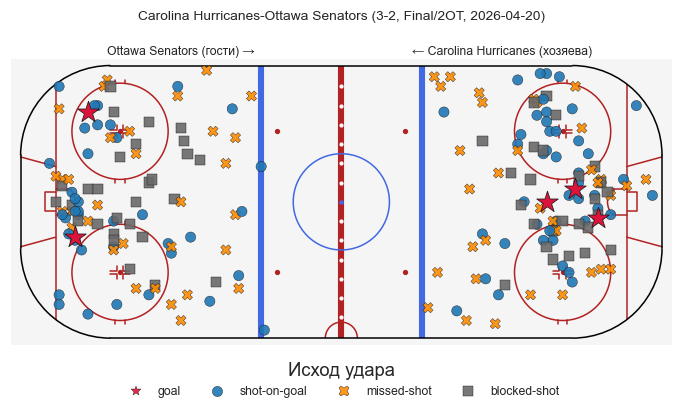

PlayType             shot-on-goal  goal  missed-shot  blocked-shot
TeamMakingthePlay                                                 
Carolina Hurricanes            46     3           34            26
Ottawa Senators                37     2           32            28


In [45]:
sg = events[(events['GameID'] == idxmax) & events['PlayType'].isin(ATTEMPTS)].copy()
sg['IsHome'] = sg['TeamMakingthePlay'] == sg['HomeTeam']
flip = (sg['HomeDefendingSide'] == 'right')
print('Совпадает ли «разворот» с нечётными периодами:', bool((flip == (sg['Period'] % 2 == 1)).all()))
sg['x'] = np.where(flip, -sg['X'], sg['X'])
sg['y'] = np.where(flip, -sg['Y'], sg['Y'])

print('Доля ударов хозяев с x>0:', round((sg.loc[sg.IsHome, 'x'] > 0).mean(), 3),
      '| доля ударов гостей с x<0:', round((sg.loc[~sg.IsHome, 'x'] < 0).mean(), 3))

palette = {'goal': 'crimson', 'shot-on-goal': 'tab:blue', 'missed-shot': 'darkorange', 'blocked-shot': 'dimgray'}
markers = {'goal': '*', 'shot-on-goal': 'o', 'missed-shot': 'X', 'blocked-shot': 's'}
plt.figure(figsize=(8, 3.6))
plot_rink()
ax = plt.gca()
sns.scatterplot(data=sg, x='x', y='y', hue='PlayType', style='PlayType', palette=palette, markers=markers,
                s=45, alpha=0.9, edgecolor='k', linewidth=0.3,
                hue_order=list(palette), style_order=list(palette), ax=ax, zorder=3)
sns.scatterplot(data=sg[sg['PlayType'] == 'goal'], x='x', y='y', color='crimson', marker='*', s=220,
                edgecolor='k', linewidth=0.5, legend=False, ax=ax, zorder=4)
ax.set_xlim(-103, 103); ax.set_ylim(-44.5, 50)
ax.axis('off'); ax.set_aspect('equal')
ax.text(-50, 46, f"{games.loc[idxmax, 'AwayTeam']} (гости) →", ha='center', fontsize=8)
ax.text(50, 46, f"← {games.loc[idxmax, 'HomeTeam']} (хозяева)", ha='center', fontsize=8)
ax.legend(title='Исход удара', loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=4, fontsize=8, frameon=False)
ax.set_title(gameInfo(idxmax), fontsize=9, y=1.0, pad=14)
plt.tight_layout(pad=0.1)
plt.savefig('figures/fig5_shots_map.png')
plt.show()

print(pd.crosstab(sg['TeamMakingthePlay'], sg['PlayType'])[ATTEMPTS])

По рисунку видно, что большинство ударов приходится на зону нападения, а в нейтральной зоне точек немного. Броски в створ (синие кружки) чаще всего сгруппированы перед воротами и между кругами вбрасывания. Промахи (оранжевые крестики) распределены шире - в том числе по краям кругов и дальше от ворот. Заблокированные броски (серые квадраты) в основном находятся между воротами и синей линией. Звёздочки обозначают пять голов: три Carolina и два Ottawa, итоговый счёт - 3:2. Хозяева нанесли 109 ударов против 99 у гостей; разница в основном связана с бросками в створ (46 против 37). Для blocked-shot координаты, вероятно, указывают место блока, а не исходного броска, поэтому серые квадраты иногда оказываются ближе к воротам, чем можно было бы ожидать.

__Пункт 16__

In [46]:
og = onice.merge(games[['AwayTeam', 'HomeTeam']].reset_index(), on='GameID')
og['Team'] = np.where(og['Side'] == 'Away', og['AwayTeam'], og['HomeTeam'])
games_played = og.drop_duplicates(['GameID', 'Player']).groupby('Player').size().rename('Games')
player_team = og.groupby('Player')['Team'].agg(lambda s: s.mode().iloc[0]).rename('Team')
print('Игроков в таблице:', len(games_played), '| у скольких больше одной команды:',
      int((og.groupby('Player')['Team'].nunique() > 1).sum()))

def top10(series, name, with_games=False, min_games=None):
    """Топ-10 по убыванию + предупреждение о ничьих на границе."""
    t = series.rename(name).to_frame()
    t = t.join(player_team).join(games_played)
    t = t.sort_values([name, 'Games'], ascending=[False, True])
    top = t.head(10)
    border = top[name].iloc[-1]
    left_out = t.index[(t[name] == border)].difference(top.index)
    if len(left_out) > 0:
        print(f'(!) ничья на границе: со значением {border} за списком остались {list(left_out)} '
              f'(при равенстве выше стоит тот, кто сыграл меньше игр)')
    return top

Игроков в таблице: 372 | у скольких больше одной команды: 0


In [47]:
goal_ev = events[events['PlayType'] == 'goal']
goals_by = goal_ev['Player1'].value_counts()
top10(goals_by, 'Goals')

(!) ничья на границе: со значением 7 за списком остались ['Alex Newhook', 'Jackson Blake'] (при равенстве выше стоит тот, кто сыграл меньше игр)


,Goals,Team,Games
Player1,,,
Brett Howden,14,Vegas Golden Knights,22
Pavel Dorofeyev,12,Vegas Golden Knights,22
Logan Stankoven,11,Carolina Hurricanes,19
Mitch Marner,10,Vegas Golden Knights,22
Nikolaj Ehlers,8,Carolina Hurricanes,18
Jordan Staal,8,Carolina Hurricanes,19
Matt Boldy,7,Minnesota Wild,11
Nathan MacKinnon,7,Colorado Avalanche,13
Mark Stone,7,Vegas Golden Knights,17


__Пункт 17__

In [48]:
assists_by = pd.concat([goal_ev['Player2'], goal_ev['Player3']]).dropna().value_counts()
print('Всего голевых передач:', int(assists_by.sum()), '| голов без передач:', int(goal_ev['Player2'].isna().sum()))
top10(assists_by, 'Assists')

Всего голевых передач: 830 | голов без передач: 27


,Assists,Team,Games
Jack Eichel,20,Vegas Golden Knights,22
Mitch Marner,19,Vegas Golden Knights,22
Jackson Blake,13,Carolina Hurricanes,19
Lane Hutson,13,Montréal Canadiens,19
Martin Necas,12,Colorado Avalanche,13
Taylor Hall,12,Carolina Hurricanes,19
Nick Suzuki,12,Montréal Canadiens,19
Shea Theodore,12,Vegas Golden Knights,22
Kirill Kaprizov,11,Minnesota Wild,11
Quinn Hughes,11,Minnesota Wild,11


__Пункт 18__

In [49]:
pts = pd.concat([goals_by.rename('Goals'), assists_by.rename('Assists')], axis=1).fillna(0).astype(int)
pts['Points'] = pts['Goals'] + pts['Assists']
top = top10(pts['Points'], 'Points')
top.join(pts[['Goals', 'Assists']])[['Team', 'Games', 'Goals', 'Assists', 'Points']]

(!) ничья на границе: со значением 16 за списком остались ['Pavel Dorofeyev'] (при равенстве выше стоит тот, кто сыграл меньше игр)


,Team,Games,Goals,Assists,Points
Mitch Marner,Vegas Golden Knights,22,10,19,29
Jack Eichel,Vegas Golden Knights,22,2,20,22
Jackson Blake,Carolina Hurricanes,19,7,13,20
Taylor Hall,Carolina Hurricanes,19,7,12,19
Nikolaj Ehlers,Carolina Hurricanes,18,8,10,18
Brett Howden,Vegas Golden Knights,22,14,4,18
Shea Theodore,Vegas Golden Knights,22,6,12,18
Logan Stankoven,Carolina Hurricanes,19,11,5,16
Nick Suzuki,Montréal Canadiens,19,4,12,16
Lane Hutson,Montréal Canadiens,19,3,13,16


__Пункт 19__

In [50]:
sog_by = events[events['PlayType'].isin(['shot-on-goal', 'goal'])]['Player1'].value_counts().rename('SOG')
sog_tbl = sog_by.to_frame().join(games_played).join(player_team)
sog_tbl['SOGperGame'] = sog_tbl['SOG'] / sog_tbl['Games']
print('--- порог ≥ 4 игр ---')
print(sog_tbl[sog_tbl['Games'] >= 4].sort_values('SOGperGame', ascending=False).head(10).round(3))
print('--- без порога ---')
print(sog_tbl.sort_values('SOGperGame', ascending=False).head(10).round(3))

--- порог ≥ 4 игр ---
                  SOG  Games                 Team  SOGperGame
Player1                                                      
Jason Robertson    30      6         Dallas Stars       5.000
Dylan Guenther     27      6         Utah Mammoth       4.500
Nikita Kucherov    31      7  Tampa Bay Lightning       4.429
Matt Boldy         48     11       Minnesota Wild       4.364
Quinton Byfield    17      4    Los Angeles Kings       4.250
Darren Raddysh     28      7  Tampa Bay Lightning       4.000
Joel Eriksson Ek   24      6       Minnesota Wild       4.000
Alex Laferriere    15      4    Los Angeles Kings       3.750
David Pastrnak     22      6        Boston Bruins       3.667
Nathan MacKinnon   47     13   Colorado Avalanche       3.615
--- без порога ---
                  SOG  Games                 Team  SOGperGame
Player1                                                      
Jason Robertson    30      6         Dallas Stars       5.000
Dylan Guenther     27      6 

__Пункт 20__

In [51]:
hits_by = events[events['PlayType'] == 'hit']['Player1'].value_counts().rename('Hits')
hit_tbl = hits_by.to_frame().join(games_played).join(player_team)
hit_tbl['HitsperGame'] = hit_tbl['Hits'] / hit_tbl['Games']
print('--- порог ≥ 4 игр ---')
print(hit_tbl[hit_tbl['Games'] >= 4].sort_values('HitsperGame', ascending=False).head(10).round(3))
print('--- без порога ---')
print(hit_tbl.sort_values('HitsperGame', ascending=False).head(10).round(3))

--- порог ≥ 4 игр ---
                  Hits  Games                  Team  HitsperGame
Player1                                                         
Lawson Crouse       38      6          Utah Mammoth        6.333
Yakov Trenin        51      9        Minnesota Wild        5.667
Dylan Cozens        22      4       Ottawa Senators        5.500
Vasily Podkolzin    32      6       Edmonton Oilers        5.333
Marcus Foligno      55     11        Minnesota Wild        5.000
Ivan Barbashev     110     22  Vegas Golden Knights        5.000
Owen Tippett        29      6   Philadelphia Flyers        4.833
William Carrier     91     19   Carolina Hurricanes        4.789
Colton Dach         23      5       Edmonton Oilers        4.600
Cole Smith         100     22  Vegas Golden Knights        4.545
--- без порога ---
                    Hits  Games                  Team  HitsperGame
Player1                                                           
Lawson Crouse         38      6          Utah

__Пункт 21__

In [52]:
gk = events.melt(id_vars=['GameID'], value_vars=goalie_cols, var_name='Slot', value_name='Goalie').dropna(subset=['Goalie'])
gk['Side'] = gk['Slot'].str[:4]
appear = gk.drop_duplicates(['GameID', 'Goalie', 'Side'])[['GameID', 'Goalie', 'Side']]


no_info = events[onice_cols].isna().all(axis=1)
prev = events.groupby('GameID')[goalie_cols].shift(1)
ev_gk = events[goalie_cols].where(~no_info, prev)

def goals_against(goal_rows, gk_cols_df):
    d = goal_rows.copy()
    d[goalie_cols] = gk_cols_df.loc[d.index]
    d['Goalie'] = np.where(d['TeamMakingthePlay'] == d['HomeTeam'], d['AwayGoalie'], d['HomeGoalie'])
    return d.dropna(subset=['Goalie']).groupby(['GameID', 'Goalie']).size().rename('GA')

ga_naive = goals_against(goal_ev, events[goalie_cols])     
ga = goals_against(goal_ev, ev_gk)                           
print('Голов без указанного вратаря до поправки:', len(goal_ev) - int(ga_naive.sum()),
      '| после поправки:', len(goal_ev) - int(ga.sum()), '(остались голы в пустые ворота)')

appear = appear.merge(ga.reset_index(), on=['GameID', 'Goalie'], how='left')
appear['GA'] = appear['GA'].fillna(0).astype(int)
appear = appear.merge(games[['AwayTeam', 'HomeTeam', 'AwayScore', 'HomeScore']].reset_index(), on='GameID')
appear['Team'] = np.where(appear['Side'] == 'Away', appear['AwayTeam'], appear['HomeTeam'])
appear['TeamGA'] = np.where(appear['Side'] == 'Away', appear['HomeScore'], appear['AwayScore'])   # голы в ворота команды за матч

shut = appear[appear['GA'] == 0]
naive = appear.drop(columns='GA').merge(ga_naive.reset_index(), on=['GameID', 'Goalie'], how='left')
print('Вратарей «без пропущенных» без поправки на пустые строки:', naive.loc[naive['GA'].isna(), 'Goalie'].nunique(),
      '| с поправкой:', shut['Goalie'].nunique())
goalies_tbl = shut.groupby('Goalie').agg(
    Team=('Team', 'first'),
    GamesNoGoals=('GameID', 'size'),
    TeamShutouts=('TeamGA', lambda s: int((s == 0).sum())),
    Games=('GameID', lambda s: ', '.join(str(i) for i in sorted(s)))
).sort_values(['GamesNoGoals', 'TeamShutouts'], ascending=False)
print('Вратарей в плей-офф:', appear['Goalie'].nunique(), '| без пропущенных хотя бы раз:', len(goalies_tbl))
print(goalies_tbl.drop(columns='Games'))
print('GamesNoGoals — матчей, где вратарь на льду не пропустил; TeamShutouts — из них матчей «на ноль» у всей команды')
goalies_tbl.drop(columns='Games')

Голов без указанного вратаря до поправки: 25 | после поправки: 3 (остались голы в пустые ворота)
Вратарей «без пропущенных» без поправки на пустые строки: 8 | с поправкой: 6
Вратарей в плей-офф: 25 | без пропущенных хотя бы раз: 6
                                   Team  GamesNoGoals  TeamShutouts
Goalie                                                             
Frederik Andersen   Carolina Hurricanes             3             3
Dan Vladar          Philadelphia Flyers             2             2
Andrei Vasilevskiy  Tampa Bay Lightning             1             1
Brandon Bussi       Carolina Hurricanes             1             1
Joonas Korpisalo          Boston Bruins             1             0
Scott Wedgewood      Colorado Avalanche             1             0
GamesNoGoals — матчей, где вратарь на льду не пропустил; TeamShutouts — из них матчей «на ноль» у всей команды


,Team,GamesNoGoals,TeamShutouts
Goalie,,,
Frederik Andersen,Carolina Hurricanes,3,3
Dan Vladar,Philadelphia Flyers,2,2
Andrei Vasilevskiy,Tampa Bay Lightning,1,1
Brandon Bussi,Carolina Hurricanes,1,1
Joonas Korpisalo,Boston Bruins,1,0
Scott Wedgewood,Colorado Avalanche,1,0


In [53]:
sh_games = games[(games['AwayScore'] == 0) | (games['HomeScore'] == 0)]
print('Матчей, закончившихся «сухим» счётом:', len(sh_games))
print('Вратарь, вышедший на замену и не пропустивший:',
      shut[shut['TeamGA'] > 0][['GameID', 'Goalie', 'Team', 'TeamGA']].to_string(index=False)
      if (shut['TeamGA'] > 0).any() else 'нет')

Матчей, закончившихся «сухим» счётом: 7
Вратарь, вышедший на замену и не пропустивший:     GameID           Goalie               Team  TeamGA
2025030114 Joonas Korpisalo      Boston Bruins       6
2025030235  Scott Wedgewood Colorado Avalanche       3


В итоговом списке шесть вратарей. Четверо полностью провели хотя бы одну игру на ноль; вместе они отвечают за все семь сухих матчей плей-офф: Frederik Andersen (Carolina) - три, Dan Vladar (Philadelphia) - два, Andrei Vasilevskiy (Tampa Bay) - один, Brandon Bussi (Carolina) - один. Последняя сухая игра Bussi - победа 3:0 над Vegas 14 июня (игра 416). Он выходил на лёд в двух матчах, но только один из них завершил без пропущенных голов. В игре 413 он сменил Andersen в начале третьего периода, а Carolina проиграла 4:5 во втором овертайме. Решающий гол в этой игре пришёлся на строку без данных об игроках; после поправки он засчитывается Bussi. Два оставшихся случая отличаются от обычного сухого матча. Joonas Korpisalo (Boston) вышел на замену в третьем периоде игры 114 при счёте 0:6 и до конца матча не пропустил. Scott Wedgewood (Colorado) заменил стартового вратаря после первого периода при счёте 0:3 и не пропускал до победного гола Colorado в овертайме (4:3, игра 235). По условию их тоже нужно учитывать, потому что они сыграли часть матча без пропущенных голов, хотя их команды в целом не завершили игру на ноль.

__Пункт 22__

Насколько результат матча "предопределён" ранним ходом игры (кто забил первым, кто выигрывает
после 1-го и 2-го периодов), и есть ли преимущество домашнего льда?


                                      Признак  Матчей  Выиграно  Доля  CI95_low  CI95_high  p (H0: 50%)
                        Хозяева выиграли матч      82        39 0.476     0.371      0.582        0.741
           Команда, забившая первой, выиграла      82        56 0.683     0.576      0.774        0.001
Лидер после 1-го периода выиграл (без ничьих)      55        39 0.709     0.579      0.812        0.003
Лидер после 2-го периода выиграл (без ничьих)      57        46 0.807     0.687      0.889        0.000

Доля побед хозяев по раундам:
        mean  sum  count
Round                   
1      0.467   21     45
2      0.500   11     22
3      0.444    4      9
4      0.500    3      6

После 2-го периода: ничья в 25 матчах из 82


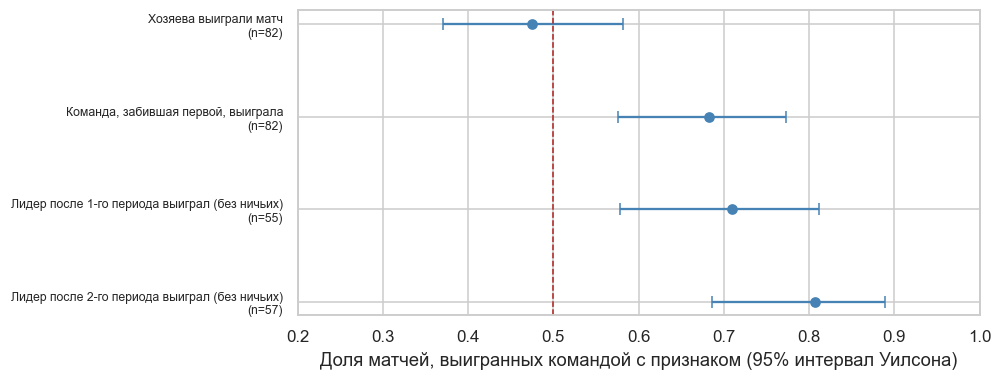

In [54]:
def wilson(k, n, z=1.96):
    p_hat = k / n
    den = 1 + z**2 / n
    centre = (p_hat + z**2 / (2 * n)) / den
    half = z * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

res = games[['AwayTeam', 'HomeTeam', 'AwayScore', 'HomeScore']].copy()
res['HomeWon'] = res['HomeScore'] > res['AwayScore']

first_goal = events[events['PlayType'] == 'goal'].groupby('GameID').first()
res['FirstScorerHome'] = (first_goal['TeamMakingthePlay'] == first_goal['HomeTeam']).reindex(res.index)

pe = events[events['PlayType'] == 'period-end'].set_index(['GameID', 'Period'])
for per in (1, 2):
    d = (pe['HomeScore'] - pe['AwayScore']).xs(per, level='Period').reindex(res.index)
    res[f'LeadHomeAfterP{per}'] = d

rows = []
def add(label, k, n):
    lo, hi = wilson(k, n)
    pv = stats.binomtest(int(k), int(n), 0.5).pvalue
    rows.append({'Признак': label, 'Матчей': int(n), 'Выиграно': int(k), 'Доля': k / n,
                 'CI95_low': lo, 'CI95_high': hi, 'p (H0: 50%)': pv})

add('Хозяева выиграли матч', res['HomeWon'].sum(), len(res))
fs_win = (res['FirstScorerHome'] == res['HomeWon'])
add('Команда, забившая первой, выиграла', fs_win.sum(), len(res))
for per in (1, 2):
    d = res[f'LeadHomeAfterP{per}']
    m = d != 0
    lead_win = ((d > 0) == res['HomeWon'])[m]
    add(f'Лидер после {per}-го периода выиграл (без ничьих)', lead_win.sum(), m.sum())

own = pd.DataFrame(rows)
print(own.round(3).to_string(index=False))

res['Round'] = res.index.astype(str).str[-3].astype(int)     # раунд плей-офф из ID игры
print('\nДоля побед хозяев по раундам:')
print(res.groupby('Round')['HomeWon'].agg(['mean', 'sum', 'count']).round(3))
print('\nПосле 2-го периода: ничья в', int((res['LeadHomeAfterP2'] == 0).sum()), 'матчах из', len(res))

fig, ax = plt.subplots(figsize=(8, 3.6))
yy = np.arange(len(own))[::-1]
ax.errorbar(own['Доля'], yy, xerr=[own['Доля'] - own['CI95_low'], own['CI95_high'] - own['Доля']],
            fmt='o', color='steelblue', capsize=4)
ax.axvline(0.5, color='firebrick', ls='--', lw=1)
ax.set_yticks(yy)
ax.set_yticklabels([f"{r['Признак']}\n(n={r['Матчей']})" for _, r in own.iterrows()], fontsize=8)
ax.set_xlabel('Доля матчей, выигранных командой с признаком (95% интервал Уилсона)')
ax.set_xlim(0.2, 1.0)
fig.savefig('figures/fig6_own_question.png')
plt.show()

Команда, забившая первой, выиграла 56 из 82 матчей - 68,3%. 95%-й доверительный интервал составляет 57,6-77,4%, p = 0,001. В этой выборке первый гол действительно связан с более высокой вероятностью победы. Если команда лидировала после второго периода, она выигрывала в 80,7% матчей (46 из 57 игр, в которых после второго периода не было ничьей). После первого периода лидер побеждал в 70,9% случаев - 39 из 55. В 25 матчах из 82 после второго периода сохранялся равный счёт, поэтому исход в них оставался открытым. Убедительного домашнего преимущества в этих данных не видно: хозяева выиграли 39 из 82 матчей, то есть 47,6% (p = 0,74). По раундам результат был таким: 21 победа в 45 матчах первого раунда, 11 из 22 во втором, 4 из 9 в третьем и 3 из 6 в финале. Эти результаты стоит трактовать осторожно. Во-первых, связь не означает причинность: более сильная команда может чаще забивать первой и в итоге выигрывать. Во-вторых, признаки связаны между собой - первый гол нередко приводит к лидерству после первого периода, поэтому это не три независимых доказательства. Наконец, в выборке всего 82 матча. Интервал для домашнего преимущества довольно широк (примерно 37-58%) и не исключает небольшого перевеса хозяев на уровне 52-55%; можно сказать лишь, что в этом плей-офф он не проявился.